<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/day20_Final_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick train.csv

Saving train.csv to train.csv


{'train.csv': b'school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other,G3\n0,1,19,0,1,1,3,3,1,2,1,0,0,0,1,1,1,0,1,4,5,3,1,2,5,0,15,12,0,1,0,0,0,0,1,0,0,0,1,0,0,12\n1,0,18,1,1,1,2,3,2,1,0,0,1,1,0,1,1,1,1,5,2,3,1,2,4,0,11,10,0,0,0,0,0,0,1,0,0,0,0,0,0,10\n0,0,19,0,1,1,2,3,1,3,1,0,0,0,0,1,1,1,1,4,1,2,1,1,3,20,13,11,0,1,0,0,0,1,0,0,0,0,1,0,1,11\n0,1,15,1,1,1,4,3,1,2,0,0,1,1,1,1,1,1,0,4,3,3,2,3,5,6,9,9,0,0,0,1,0,1,0,0,1,0,0,1,0,10\n0,1,17,1,0,0,4,1,2,1,0,0,0,1,1,1,1,1,1,4,5,4,2,4,5,20,8,8,0,0,1,0,0,1,0,0,1,0,0,1,0,8\n1,0,18,1,0,1,3,1,1,2,0,0,1,1,0,1,1,1,0,4,3,4,1,1,1,0,7,9,0,0,0,1,0,0,1,0,0,0,0,1,0,8\n0,0,16,1,1,1,4,4,1,3,0,0,1,1,1,1,1,1,0,3,2,3,1,2,2,6,13,14,0,0,1,0,0,0,1,0,0,0,

In [3]:
# Cell 1: setup, same data, same outer folds as Days 16-19 (first two repeats)
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import (RepeatedKFold, RepeatedStratifiedKFold, KFold, StratifiedKFold,
                                     RandomizedSearchCV, cross_validate)
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              RandomForestClassifier, GradientBoostingClassifier)
from sklearn.linear_model import Ridge, RidgeCV, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor

sns.set_theme(style="whitegrid")
train = pd.read_csv("train.csv")
y = train["G3"]
y_risk = (y < 10).astype(int)
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
feature_sets = {"early (no G1/G2)": X_early, "all features": X_all}

FAST = False                       # set True for a quicker, rougher run (about half the time)
SCALE = 0.5 if FAST else 1.0
n_rep = 1 if FAST else 2

outer_reg = RepeatedKFold(n_splits=5, n_repeats=n_rep, random_state=42)
inner_reg = KFold(n_splits=5, shuffle=True, random_state=1)
outer_clf = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_rep, random_state=42)
inner_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
rmse_scoring = "neg_root_mean_squared_error"

def py(o):                         # makes numpy values safe for JSON
    if isinstance(o, dict): return {k: py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [py(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    return o

print("Training students:", len(train), "| outer folds per model:", 5 * n_rep)

Training students: 285 | outer folds per model: 10


In [4]:
# Cell 2: the candidates, their search spaces, and the Day 17-19 hand-set versions for comparison
def n_it(k):
    return max(4, int(k * SCALE))

def reg_candidates():
    return {
        "Ridge": (make_pipeline(StandardScaler(), Ridge()),
                  {"ridge__alpha": loguniform(1e-2, 1e3)}, n_it(15)),
        "Random Forest": (RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1),
                          {"max_features": uniform(0.1, 0.9),
                           "min_samples_leaf": randint(1, 15),
                           "max_depth": [None, 4, 6, 8]}, n_it(12)),
        "Gradient Boosting": (GradientBoostingRegressor(random_state=42),
                              {"learning_rate": loguniform(0.01, 0.2),
                               "n_estimators": randint(50, 400),
                               "max_depth": randint(1, 4),
                               "subsample": uniform(0.6, 0.4),
                               "min_samples_leaf": randint(1, 15)}, n_it(12)),
    }

def reg_defaults():                # the settings used on Days 16-19
    return {
        "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 40))),
        "Random Forest": RandomForestRegressor(n_estimators=300, max_features=0.33, min_samples_leaf=3,
                                               random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=2,
                                                       subsample=0.8, random_state=42),
    }

for m, (_, space, k) in reg_candidates().items():
    print(f"{m:18s} {k:2d} random settings per search | tuning: {list(space)}")

Ridge              15 random settings per search | tuning: ['ridge__alpha']
Random Forest      12 random settings per search | tuning: ['max_features', 'min_samples_leaf', 'max_depth']
Gradient Boosting  12 random settings per search | tuning: ['learning_rate', 'n_estimators', 'max_depth', 'subsample', 'min_samples_leaf']


In [5]:
# Cell 3: nested cross-validation for regression (the slow cell)
res, base_scores = {}, {}
t0 = time.time()

for fname, X in feature_sets.items():
    base_scores[fname] = -cross_validate(DummyRegressor(), X, y, cv=outer_reg,
                                         scoring=rmse_scoring)["test_score"]
    for mname, (model, space, k) in reg_candidates().items():
        search = RandomizedSearchCV(model, space, n_iter=k, cv=inner_reg, scoring=rmse_scoring,
                                    random_state=0, n_jobs=-1)
        r = cross_validate(search, X, y, cv=outer_reg, scoring=rmse_scoring, return_estimator=True)
        d = cross_validate(reg_defaults()[mname], X, y, cv=outer_reg, scoring=rmse_scoring)
        res[(fname, mname)] = {"tuned": -r["test_score"], "default": -d["test_score"],
                               "params": [e.best_params_ for e in r["estimator"]]}
        print(f"{fname:18s} {mname:18s} done | elapsed {(time.time() - t0) / 60:.1f} min")

early (no G1/G2)   Ridge              done | elapsed 0.1 min
early (no G1/G2)   Random Forest      done | elapsed 3.0 min
early (no G1/G2)   Gradient Boosting  done | elapsed 4.5 min
all features       Ridge              done | elapsed 4.6 min
all features       Random Forest      done | elapsed 7.4 min
all features       Gradient Boosting  done | elapsed 8.9 min


In [6]:
# Cell 4: tuned (nested) vs the Day 17-19 settings vs the baseline
rows = []
for fname in feature_sets:
    base = base_scores[fname]
    for mname in ["Ridge", "Random Forest", "Gradient Boosting"]:
        t, d = res[(fname, mname)]["tuned"], res[(fname, mname)]["default"]
        rows.append({"features": fname, "model": mname,
                     "default RMSE": round(d.mean(), 3),
                     "tuned RMSE (nested)": round(t.mean(), 3),
                     "std": round(t.std(), 3),
                     "gain from tuning": round(d.mean() - t.mean(), 3),
                     "gain over baseline %": round(100 * (base - t).mean() / base.mean(), 1),
                     "folds better than baseline": f"{(base - t > 0).sum()}/{len(t)}"})
reg_table = pd.DataFrame(rows)
print("Baseline CV RMSE:", {k: round(v.mean(), 3) for k, v in base_scores.items()})
reg_table

Baseline CV RMSE: {'early (no G1/G2)': np.float64(3.266), 'all features': np.float64(3.266)}


,features,model,default RMSE,tuned RMSE (nested),std,gain from tuning,gain over baseline %,folds better than baseline
0,early (no G1/G2),Ridge,2.968,2.959,0.156,0.009,9.4,10/10
1,early (no G1/G2),Random Forest,3.000,3.046,0.172,-0.046,6.7,9/10
2,early (no G1/G2),Gradient Boosting,3.003,2.989,0.157,0.014,8.5,10/10
3,all features,Ridge,0.914,0.916,0.073,-0.002,71.9,10/10
4,all features,Random Forest,1.046,0.897,0.085,0.149,72.5,10/10
5,all features,Gradient Boosting,0.869,0.867,0.064,0.002,73.4,10/10


In [7]:
# Cell 5: how stable are the chosen settings across the outer folds?
for fname in feature_sets:
    for mname in ["Gradient Boosting", "Random Forest"]:
        p = pd.DataFrame(res[(fname, mname)]["params"])
        print(f"\n{fname} | {mname}: settings chosen in each outer fold")
        print(p.round(3).to_string(index=False))


early (no G1/G2) | Gradient Boosting: settings chosen in each outer fold
 learning_rate  max_depth  min_samples_leaf  n_estimators  subsample
         0.050          1                11           294      0.789
         0.049          1                 2           215      0.934
         0.050          1                11           294      0.789
         0.050          1                11           294      0.789
         0.037          2                 8           107      0.867
         0.050          1                11           294      0.789
         0.049          1                 2           215      0.934
         0.050          1                11           294      0.789
         0.037          2                 8           107      0.867
         0.037          2                 8           107      0.867

early (no G1/G2) | Random Forest: settings chosen in each outer fold
 max_depth  max_features  min_samples_leaf
       8.0         0.568                 4
       NaN 

In [8]:
# Cell 6: apply the selection rule and write the reasoning down
rank = {"Ridge": 1, "Random Forest": 2, "Gradient Boosting": 3}
col = "tuned RMSE (nested)"
chosen_reg = {}

for fname in feature_sets:
    cand = reg_table[reg_table.features == fname]
    best = cand.loc[cand[col].idxmin()]
    ok = cand[cand[col] <= best[col] + best["std"]].copy()          # within 1 std of the best
    ok["rank"] = ok["model"].map(rank)
    pick = ok.sort_values(["rank", col]).iloc[0]
    better, total = [int(v) for v in pick["folds better than baseline"].split("/")]
    useful = bool(better / total >= 0.8 and pick["gain over baseline %"] >= 10)
    chosen_reg[fname] = {"model": pick["model"], "nested_cv_rmse": float(pick[col]),
                         "std": float(pick["std"]),
                         "gain_over_baseline_pct": float(pick["gain over baseline %"]),
                         "folds_better_than_baseline": pick["folds better than baseline"],
                         "useful": useful}
    print(f"{fname:18s} lowest nested RMSE: {best['model']} ({best[col]:.3f} +/- {best['std']:.3f})")
    print(f"{'':18s} candidates within 1 std: {list(ok['model'])}")
    print(f"{'':18s} CHOSEN: {pick['model']} | RMSE {pick[col]:.3f} | "
          f"{pick['gain over baseline %']}% better than baseline in {pick['folds better than baseline']} folds"
          f" | useful: {useful}\n")

early (no G1/G2)   lowest nested RMSE: Ridge (2.959 +/- 0.156)
                   candidates within 1 std: ['Ridge', 'Random Forest', 'Gradient Boosting']
                   CHOSEN: Ridge | RMSE 2.959 | 9.4% better than baseline in 10/10 folds | useful: False

all features       lowest nested RMSE: Gradient Boosting (0.867 +/- 0.064)
                   candidates within 1 std: ['Ridge', 'Random Forest', 'Gradient Boosting']
                   CHOSEN: Ridge | RMSE 0.916 | 71.9% better than baseline in 10/10 folds | useful: True



In [9]:
# Cell 7: final settings, one search per chosen model on ALL training students
final_reg = {}
for fname, info in chosen_reg.items():
    model, space, _ = reg_candidates()[info["model"]]
    gs = RandomizedSearchCV(model, space, n_iter=n_it(40), cv=inner_reg, scoring=rmse_scoring,
                            random_state=0, n_jobs=-1).fit(feature_sets[fname], y)
    final_reg[fname] = {"model": info["model"], "params": py(gs.best_params_),
                        "refit_cv_rmse_OPTIMISTIC_do_not_report": float(-gs.best_score_)}
    print(f"{fname:18s} {info['model']:18s} final settings: {py(gs.best_params_)}")
    print(f"{'':18s} this search's own score is {-gs.best_score_:.3f} (optimistic), "
          f"the honest figure is the nested {info['nested_cv_rmse']:.3f}\n")

early (no G1/G2)   Ridge              final settings: {'ridge__alpha': 99.03593841281113}
                   this search's own score is 2.919 (optimistic), the honest figure is the nested 2.959

all features       Ridge              final settings: {'ridge__alpha': 2.0295362430434727}
                   this search's own score is 0.914 (optimistic), the honest figure is the nested 0.916



In [10]:
# Cell 8: the same procedure for the at-risk classifier (ROC AUC, nested; the slow cell again)
def clf_candidates():
    return {
        "Logistic": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                     {"logisticregression__C": loguniform(1e-3, 1e2)}, n_it(12)),
        "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1),
                          {"max_features": [0.1, 0.2, 0.33, 0.5],
                           "min_samples_leaf": randint(1, 15),
                           "max_depth": [None, 4, 6, 8]}, n_it(10)),
        "Gradient Boosting": (GradientBoostingClassifier(random_state=42),
                              {"learning_rate": loguniform(0.01, 0.2),
                               "n_estimators": randint(50, 300),
                               "max_depth": randint(1, 4),
                               "subsample": uniform(0.6, 0.4),
                               "min_samples_leaf": randint(1, 15)}, n_it(10)),
    }

clf_res, rows, t0 = {}, [], time.time()
for fname, X in feature_sets.items():
    for mname, (model, space, k) in clf_candidates().items():
        search = RandomizedSearchCV(model, space, n_iter=k, cv=inner_clf, scoring="roc_auc",
                                    random_state=0, n_jobs=-1)
        r = cross_validate(search, X, y_risk, cv=outer_clf, scoring="roc_auc")
        clf_res[(fname, mname)] = r["test_score"]
        rows.append({"features": fname, "model": mname,
                     "nested ROC AUC": round(r["test_score"].mean(), 3),
                     "std": round(r["test_score"].std(), 3)})
        print(f"{fname:18s} {mname:18s} done | elapsed {(time.time() - t0) / 60:.1f} min")

clf_table = pd.DataFrame(rows)
print(f"\nAt-risk share of training students: {y_risk.mean():.1%} | AUC of guessing: 0.5")
clf_table

early (no G1/G2)   Logistic           done | elapsed 0.1 min
early (no G1/G2)   Random Forest      done | elapsed 2.5 min
early (no G1/G2)   Gradient Boosting  done | elapsed 3.6 min
all features       Logistic           done | elapsed 3.7 min
all features       Random Forest      done | elapsed 6.0 min
all features       Gradient Boosting  done | elapsed 7.2 min

At-risk share of training students: 25.6% | AUC of guessing: 0.5


,features,model,nested ROC AUC,std
0,early (no G1/G2),Logistic,0.657,0.080
1,early (no G1/G2),Random Forest,0.659,0.062
2,early (no G1/G2),Gradient Boosting,0.669,0.060
3,all features,Logistic,0.943,0.024
4,all features,Random Forest,0.963,0.022
5,all features,Gradient Boosting,0.962,0.020


early (no G1/G2)   CHOSEN: Logistic | nested AUC 0.657 +/- 0.080 | usable (AUC >= 0.70): False
                   final settings: {'logisticregression__C': 0.08264328927007726}

all features       CHOSEN: Logistic | nested AUC 0.943 +/- 0.024 | usable (AUC >= 0.70): True
                   final settings: {'logisticregression__C': 1.032326035197657}



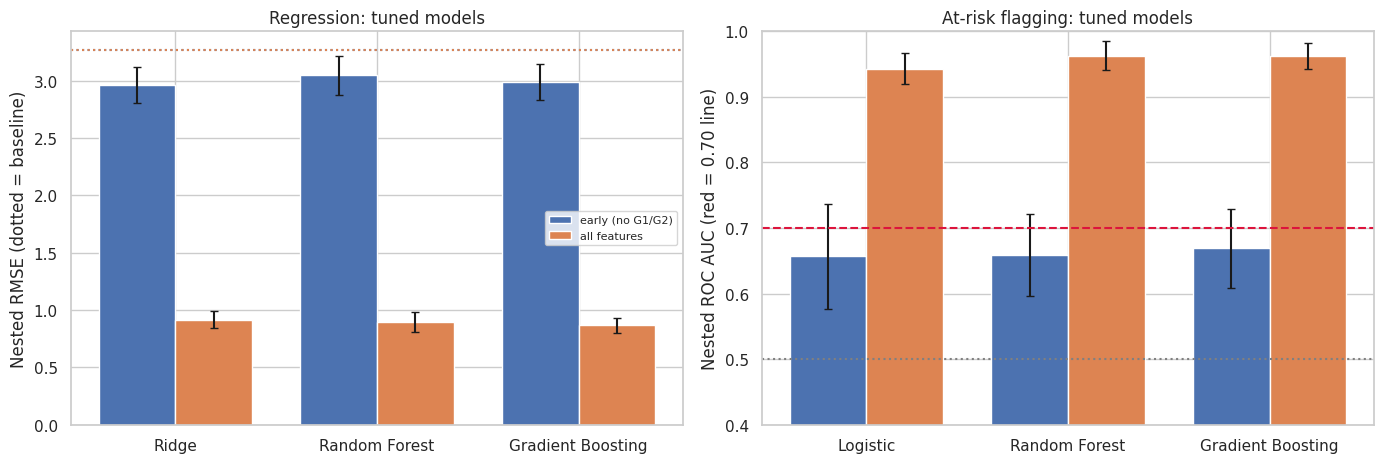

Saved final_config.json, phase4_day20_regression.csv, phase4_day20_classification.csv


In [11]:
# Cell 9: choose the classifier, refit once, and save the final configuration
chosen_clf, final_clf = {}, {}
for fname, X in feature_sets.items():
    cand = clf_table[clf_table.features == fname]
    best = cand.loc[cand["nested ROC AUC"].idxmax()]
    ok = cand[cand["nested ROC AUC"] >= best["nested ROC AUC"] - best["std"]].copy()
    ok["rank"] = ok["model"].map(rank | {"Logistic": 1, "Ridge": 1})
    pick = ok.sort_values(["rank", "nested ROC AUC"], ascending=[True, False]).iloc[0]
    usable = bool(pick["nested ROC AUC"] >= 0.70)
    chosen_clf[fname] = {"model": pick["model"], "nested_roc_auc": float(pick["nested ROC AUC"]),
                         "std": float(pick["std"]), "usable": usable}

    model, space, _ = clf_candidates()[pick["model"]]
    gs = RandomizedSearchCV(model, space, n_iter=n_it(30), cv=inner_clf, scoring="roc_auc",
                            random_state=0, n_jobs=-1).fit(X, y_risk)
    final_clf[fname] = {"model": pick["model"], "params": py(gs.best_params_),
                        "refit_cv_auc_OPTIMISTIC_do_not_report": float(gs.best_score_)}
    print(f"{fname:18s} CHOSEN: {pick['model']} | nested AUC {pick['nested ROC AUC']:.3f} "
          f"+/- {pick['std']:.3f} | usable (AUC >= 0.70): {usable}")
    print(f"{'':18s} final settings: {py(gs.best_params_)}\n")

final_config = {
    "design": {"outer_cv": f"RepeatedKFold 5 splits x {n_rep} repeats, random_state=42",
               "inner_cv": "5-fold, shuffle, random_state=1", "search": "RandomizedSearchCV",
               "fast_mode": FAST},
    "rules": {"selection": "simplest model within 1 std of the best nested score",
              "regression_useful": ">=80% folds better than baseline and >=10% lower RMSE",
              "classification_usable": "nested ROC AUC >= 0.70"},
    "regression": {f: {**chosen_reg[f], **final_reg[f]} for f in feature_sets},
    "classification": {f: {**chosen_clf[f], **final_clf[f]} for f in feature_sets},
    "baseline_cv_rmse": {k: float(v.mean()) for k, v in base_scores.items()},
    "test_set_status": "sealed until Day 21",
}
with open("final_config.json", "w") as f:
    json.dump(py(final_config), f, indent=2)
reg_table.to_csv("phase4_day20_regression.csv", index=False)
clf_table.to_csv("phase4_day20_classification.csv", index=False)

# summary figure
order = ["Ridge", "Random Forest", "Gradient Boosting"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
w = 0.38
for i, fname in enumerate(feature_sets):
    sub = reg_table[reg_table.features == fname].set_index("model").loc[order]
    axes[0].bar(np.arange(3) + i * w, sub["tuned RMSE (nested)"], w, yerr=sub["std"], capsize=3, label=fname)
    axes[0].axhline(base_scores[fname].mean(), linestyle=":", color=f"C{i}")
    sub2 = clf_table[clf_table.features == fname].set_index("model").loc[["Logistic"] + order[1:]]
    axes[1].bar(np.arange(3) + i * w, sub2["nested ROC AUC"], w, yerr=sub2["std"], capsize=3, label=fname)
axes[0].set_xticks(np.arange(3) + w / 2); axes[0].set_xticklabels(order)
axes[0].set_ylabel("Nested RMSE (dotted = baseline)"); axes[0].set_title("Regression: tuned models"); axes[0].legend(fontsize=8)
axes[1].axhline(0.5, color="gray", linestyle=":"); axes[1].axhline(0.7, color="crimson", linestyle="--")
axes[1].set_xticks(np.arange(3) + w / 2); axes[1].set_xticklabels(["Logistic"] + order[1:])
axes[1].set_ylim(0.4, 1.0); axes[1].set_ylabel("Nested ROC AUC (red = 0.70 line)"); axes[1].set_title("At-risk flagging: tuned models")
plt.tight_layout()
plt.savefig("final_tuning.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved final_config.json, phase4_day20_regression.csv, phase4_day20_classification.csv")